# 02 · Análisis exploratorio visual y storytelling
**Audiencia:** Gerente de Contenidos y Adquisición de StreamView Analytics.
**Pregunta central:** *¿Qué contenido debería adquirir y priorizar StreamView para crecer en popularidad y calidad?*

Cada gráfico tiene un **título-hallazgo** (lo que hay que ver), un subtítulo con **período y alcance** (regla 7)
y una justificación de la forma elegida. Estructura narrativa (sección 23 del caso):
**¿Qué está ocurriendo? → ¿Por qué? → ¿Qué evidencia lo demuestra? → ¿Qué decisiones tomar?**

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import plotly.io as pio
pio.renderers.default = "png"          # imágenes estáticas: el notebook se ve igual en cualquier visor
pio.renderers["png"].width = 1100
pio.renderers["png"].scale = 1.5
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
import theme as T, charts as C
from data import load
D = load(); cat, gen, pais, pers = D["cat"], D["gen"], D["pais"], D["pers"]

## KPIs del catálogo

In [2]:
K = C.kpis(cat, gen, pais)
pd.Series({k: (C.fmt(v, 2) if isinstance(v, float) and v < 100 else C.fmt(v)) for k, v in K.items()}).to_frame("valor")

,valor
Total de contenidos,32.000
Películas,16.000
Series,16.000
Países representados,147
Idiomas,82
Géneros,22
Popularidad mediana,"22,06"
Calificación promedio,"6,63"
Títulos con valoración válida,"0,64"
Películas con datos financieros,3.500


---
# Acto 1 · ¿Qué está ocurriendo? — Cómo es el catálogo hoy
### Q: ¿Cómo se distribuye el catálogo y qué géneros predominan?
**Forma:** treemap (parte-todo jerárquico: tipo → género). El área permite ver el peso relativo sin leer números.

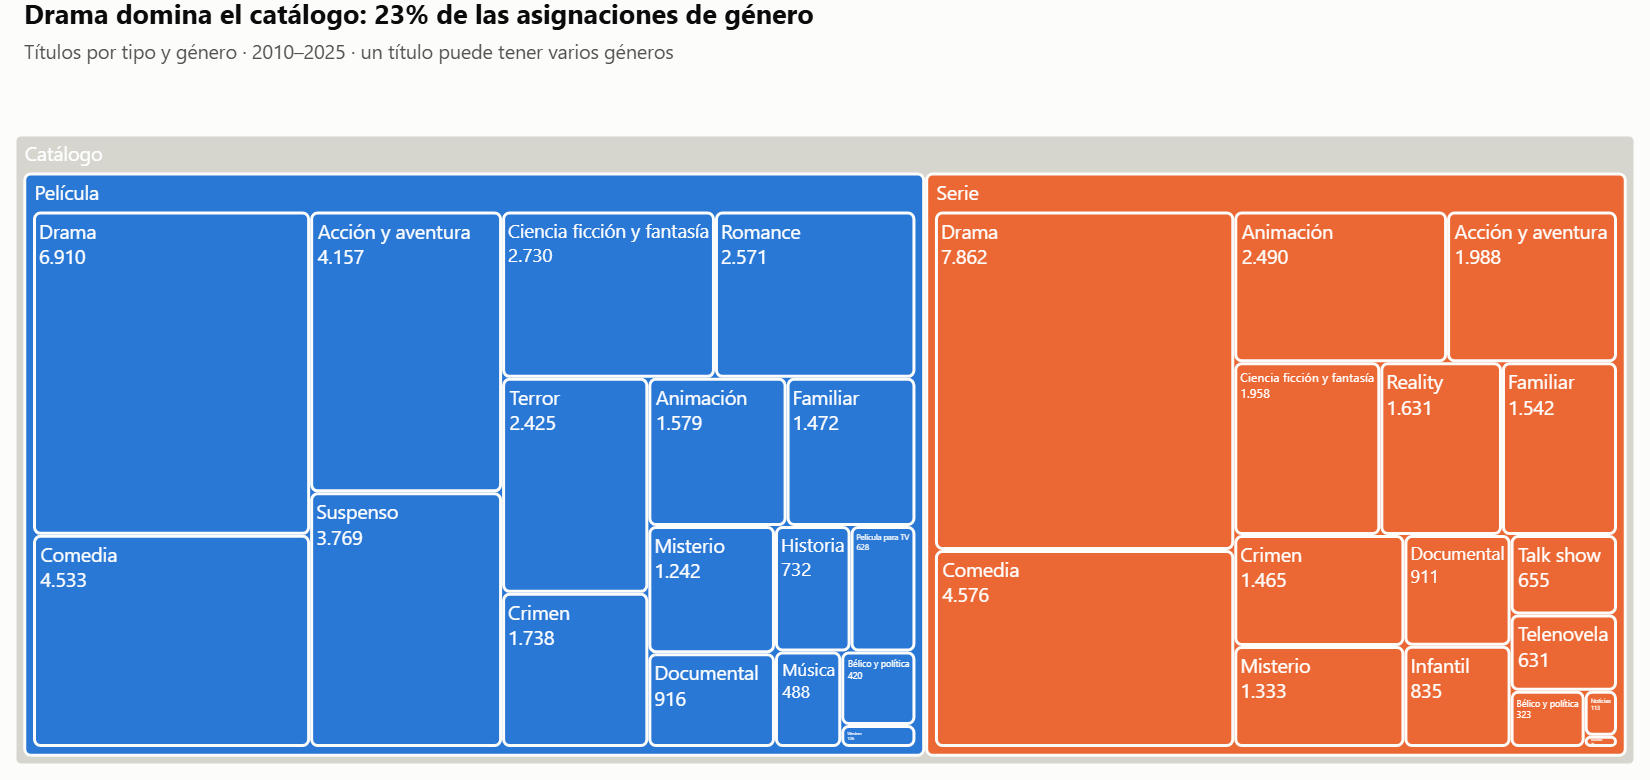

In [3]:
C.fig_treemap_generos(gen).show()

**Lectura:** el catálogo es 50/50 películas–series (por diseño de la muestra). **Drama** domina ambos tipos
(23% de las asignaciones de género), seguido de Comedia. Géneros con fuerte demanda como Animación,
Familiar o Telenovela ocupan áreas pequeñas.
### Q: ¿Qué idiomas concentran más contenido?
**Forma:** small multiples de barras horizontales (oferta vs. popularidad) en vez de un eje dual (anti-patrón).

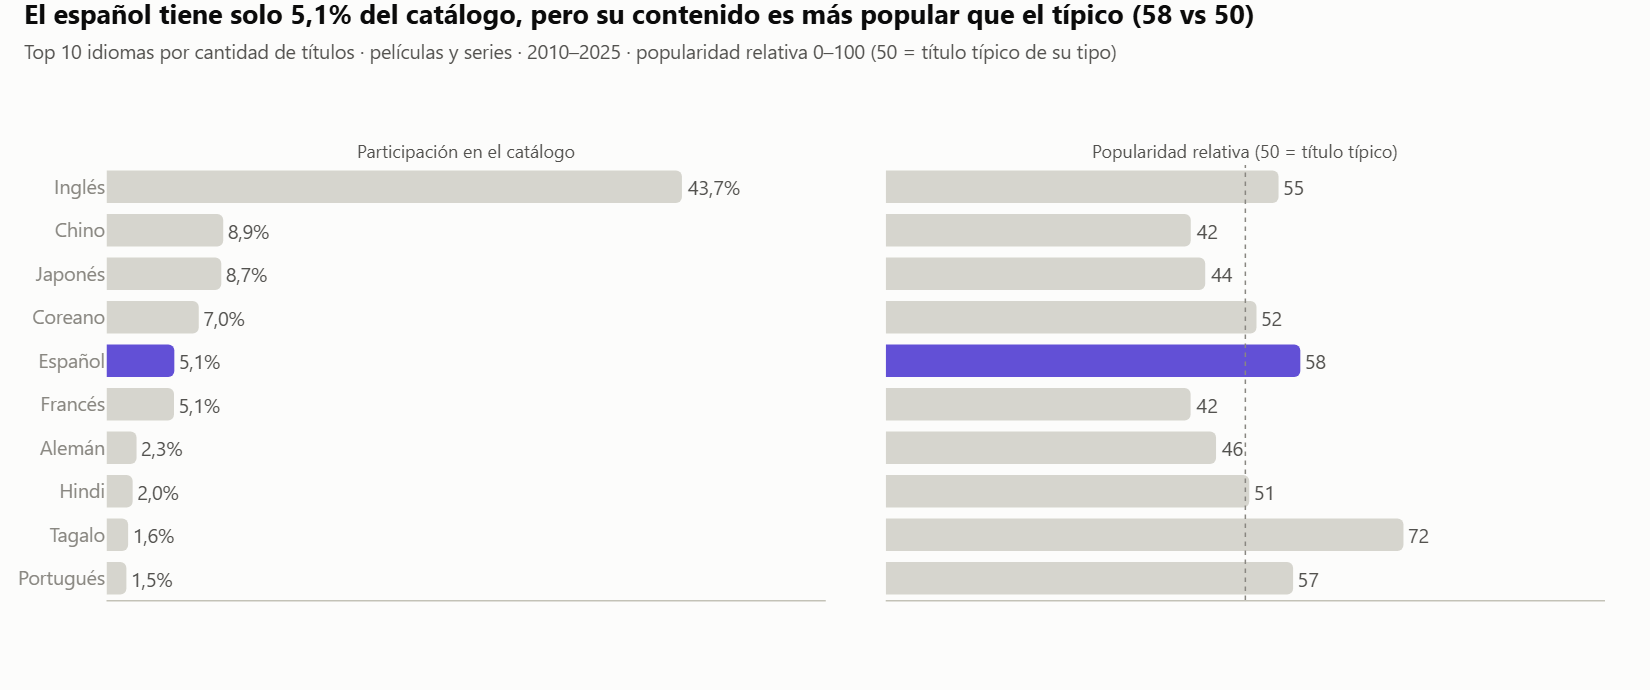

In [4]:
C.fig_idiomas(cat).show()

**Lectura:** el inglés concentra el 44% del catálogo. El **español** tiene solo 5,1% pero su popularidad mediana
es **más popular que el título típico (58 sobre 100; típico = 50)**, más que el inglés (55). Para una plataforma latinoamericana, es una
señal clara de sub-oferta. El tagalo (Filipinas) es otro idioma con demanda alta relativa a su oferta.
### Q: ¿Qué países producen más contenido?
**Forma:** mapa coroplético con escala secuencial de un solo tono y **escala logarítmica** (EE.UU. aplastaría al resto).

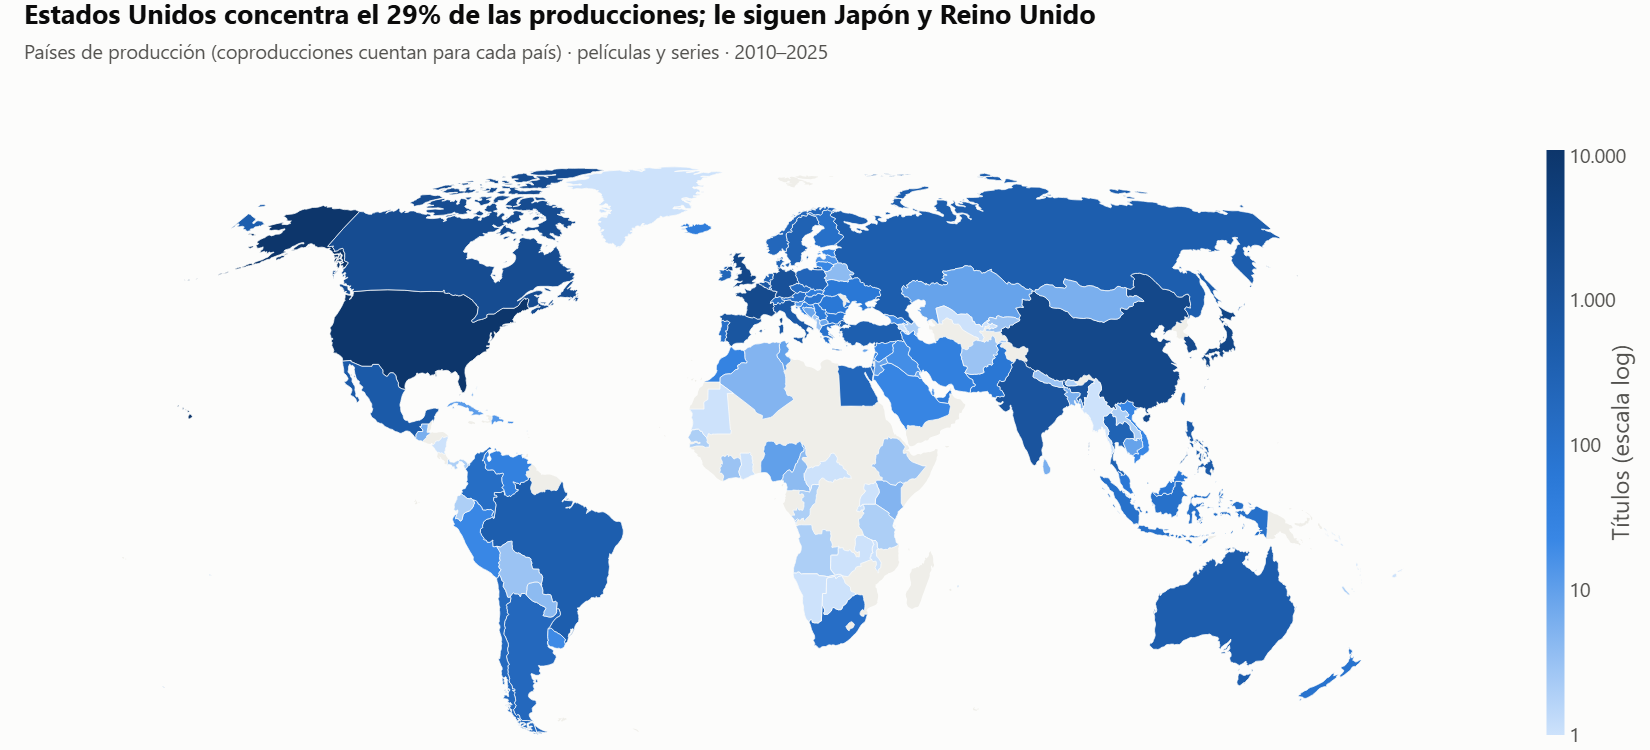

In [5]:
C.fig_mapa(pais).show()

In [6]:
C.tabla_paises(pais, 50).head(12)

,pais,iso3,titulos,percentil_pop,nota_media,peliculas,share
44,Estados Unidos,USA,10956,0.586688,6.492040,7762,0.291112
69,Japón,JPN,2871,0.458750,7.216565,990,0.076285
113,Reino Unido,GBR,2609,0.539500,6.575078,1743,0.069324
29,China,CHN,2399,0.462625,6.915474,499,0.063744
32,Corea del Sur,KOR,2174,0.521016,7.104177,875,0.057765
51,Francia,FRA,2108,0.451812,6.438279,1701,0.056012
25,Canadá,CAN,1716,0.546031,6.348912,1063,0.045596
2,Alemania,DEU,1160,0.490375,6.543526,691,0.030822
61,India,IND,912,0.510641,6.581451,528,0.024233
43,España,ESP,822,0.499766,6.523272,563,0.021841


### Q: ¿Cómo ha evolucionado el catálogo?
Como hay 1.000 títulos por año (muestra estratificada), se analiza la **composición**:
**Forma:** áreas apiladas al 100% con solo 3 grupos por género principal (cada título cuenta una vez), con etiquetas directas.

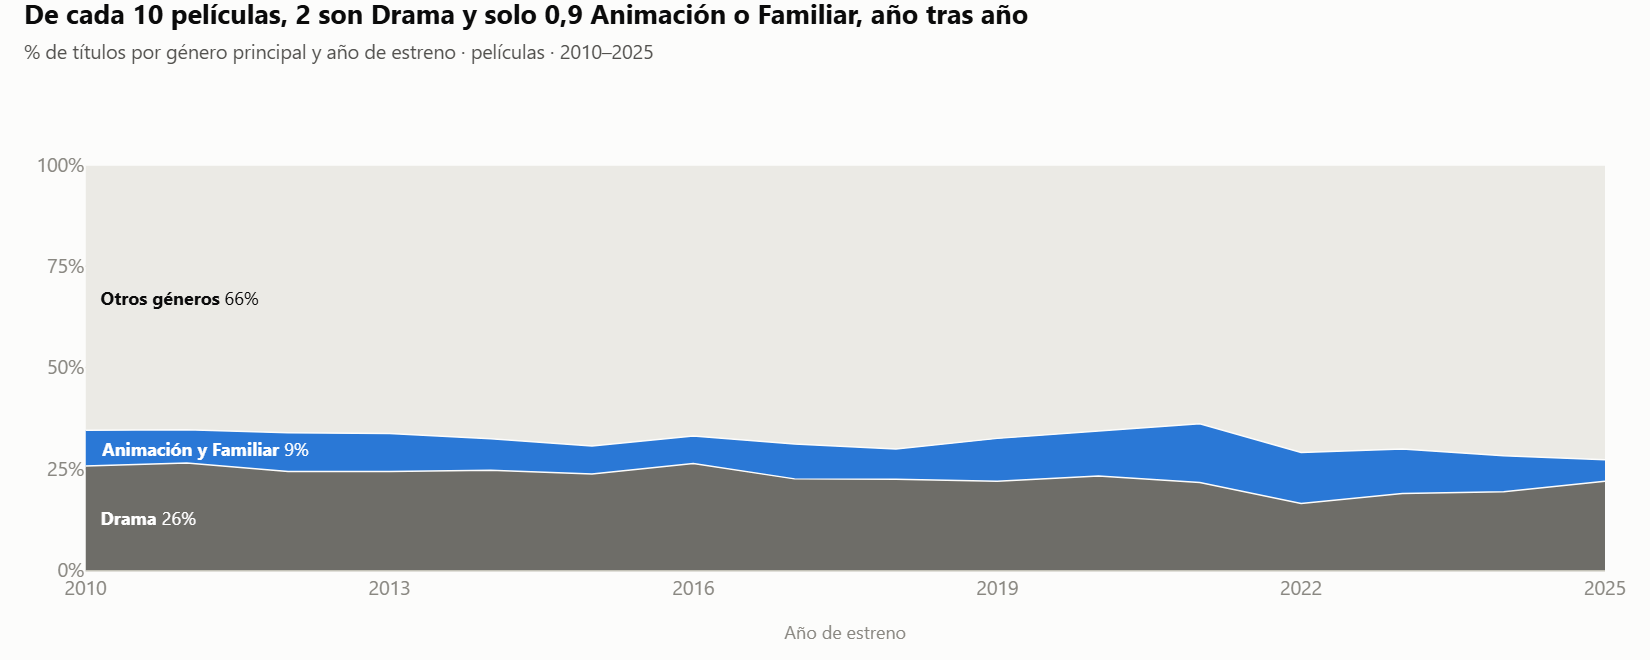

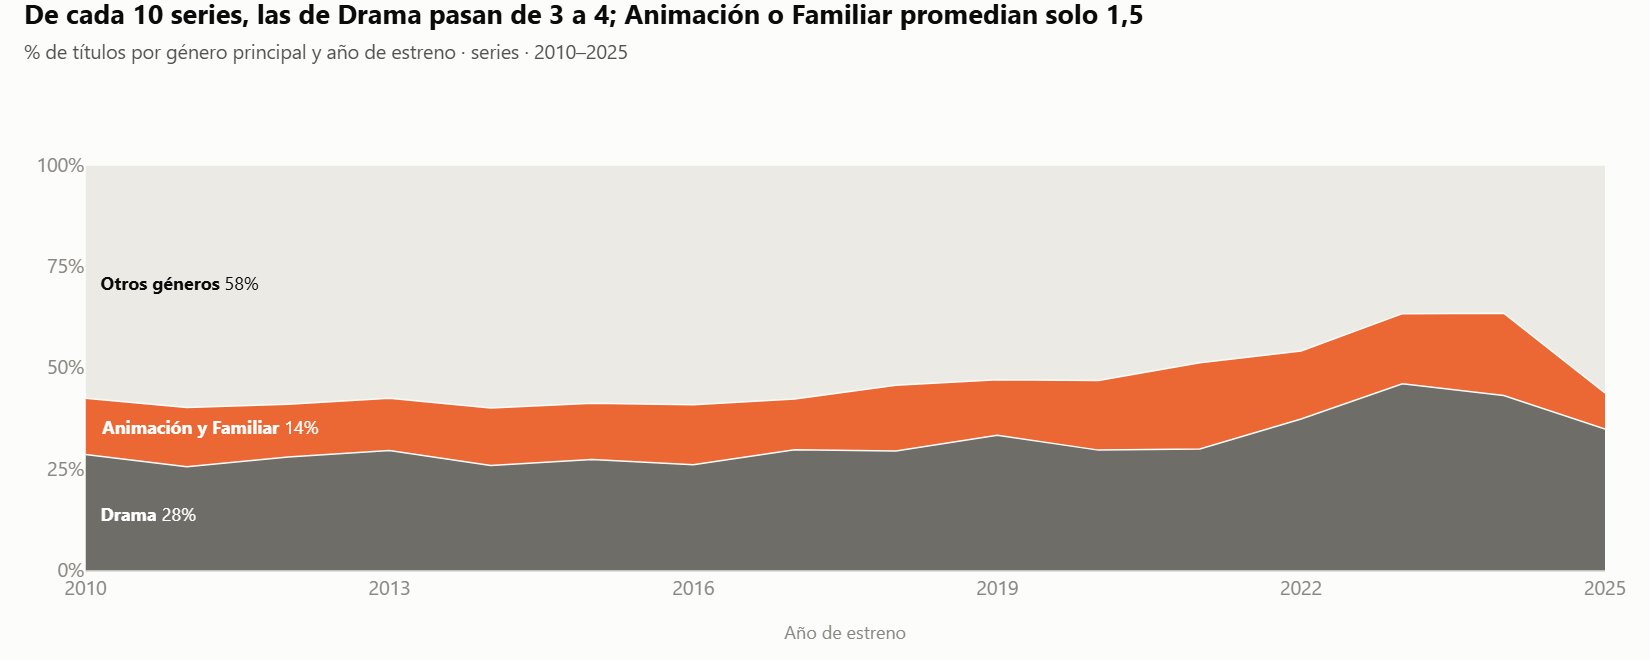

In [7]:
C.fig_mix_generos_tiempo(cat, 'Película').show()
C.fig_mix_generos_tiempo(cat, 'Serie').show()

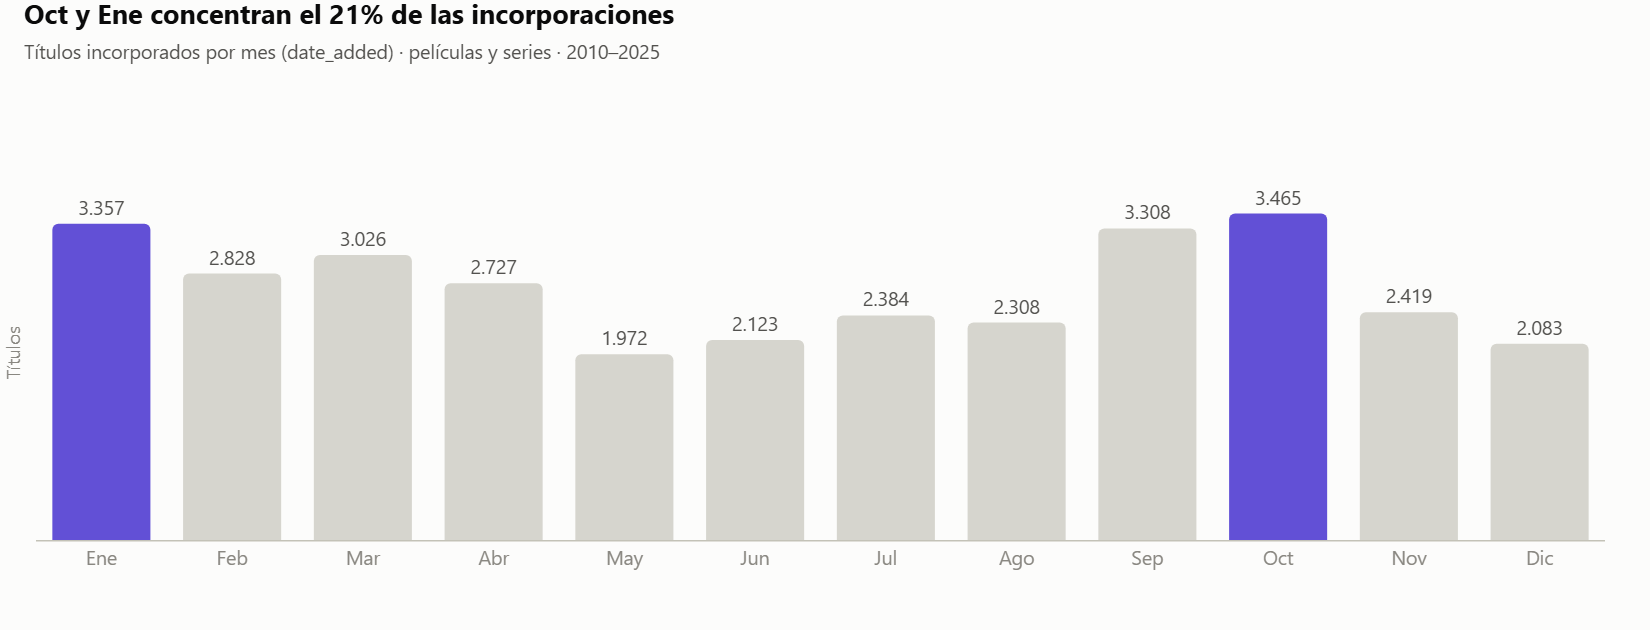

In [8]:
C.fig_incorporaciones_mes(cat).show()

**Lectura:** de cada 10 películas, 2 tienen Drama como género principal y menos de 1 es Animación o Familiar, año tras año; en series, Drama sube de ~3 a ~4 de cada 10 en los últimos años. Las
incorporaciones se concentran en **septiembre-octubre y enero**, útil para planificar el calendario de lanzamientos.

---
# Acto 2 · ¿Por qué ocurre? — Popularidad y valoración
### Q: ¿Existen diferencias entre películas y series?
**Forma:** box plot en escala log (distribución asimétrica) e histograma agrupado (misma escala 0–10).

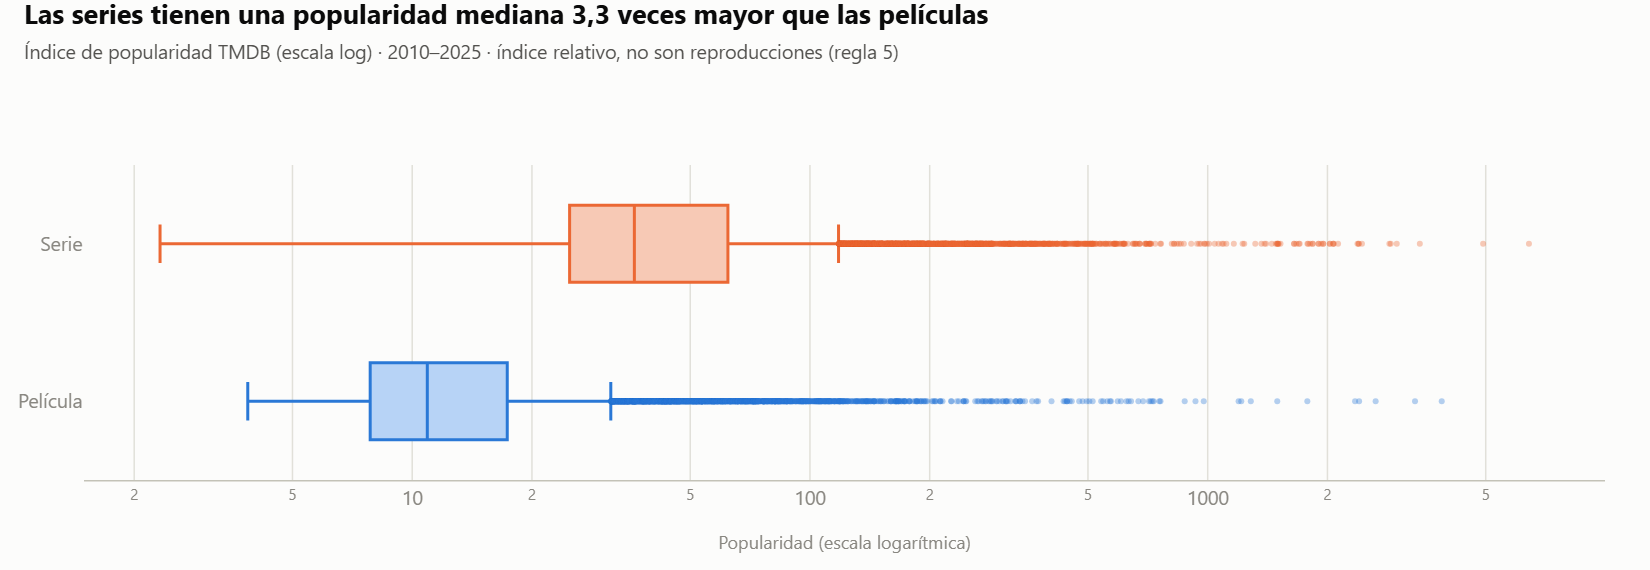

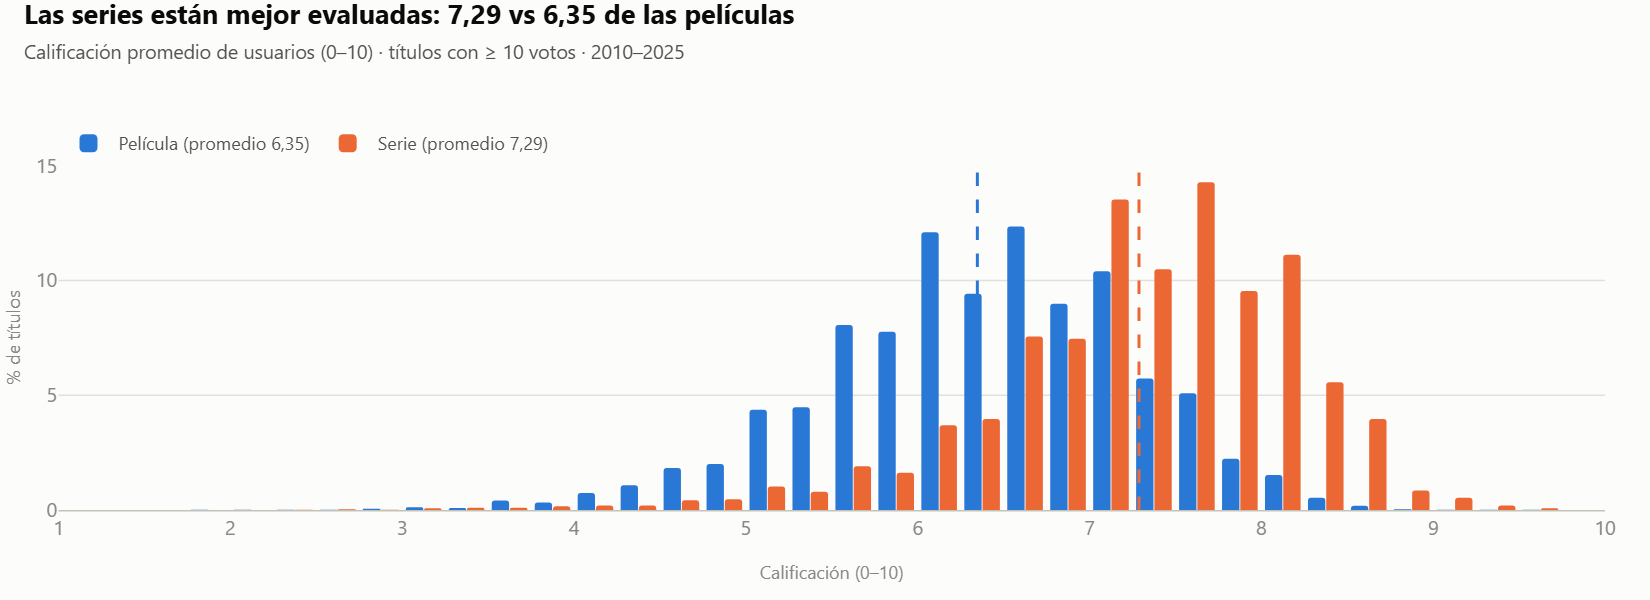

In [9]:
C.fig_dist_popularidad(cat).show()
C.fig_dist_nota(cat).show()

**Lectura:** las series tienen popularidad mediana 3,3x mayor y mejor calificación (7,29 vs 6,35).
⚠️ Cautela (regla 2): TMDB calcula la popularidad por separado para cada tipo; por eso las comparaciones de género
usan el **percentil dentro de cada tipo**.
### Q: ¿Existe relación entre popularidad y calificación?
**Forma:** dispersión (dos variables cuantitativas), eje X log, transparencia contra sobre-impresión; correlación de Spearman.

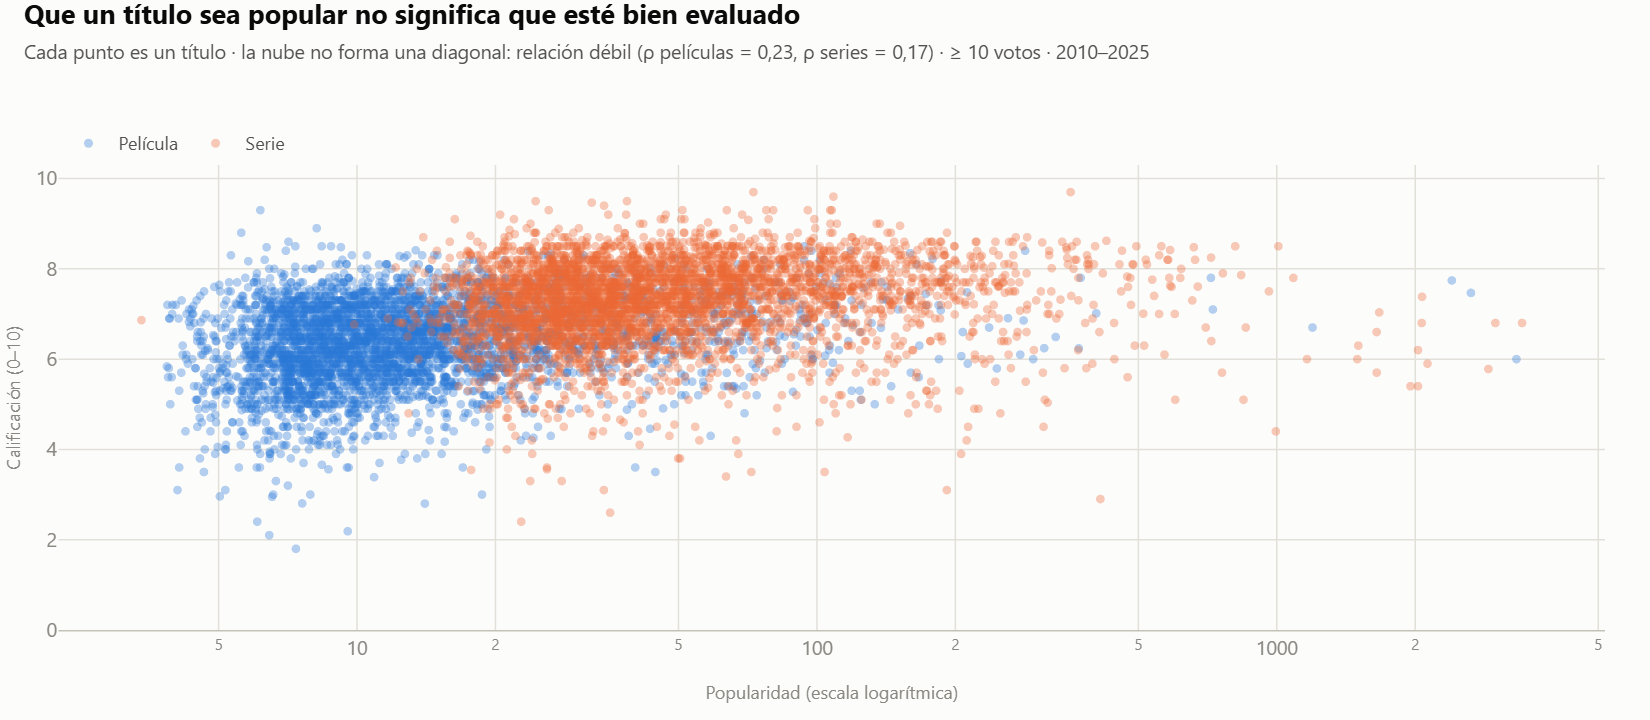

In [10]:
C.fig_pop_vs_nota(cat).show()

**Lectura:** la nube no forma una diagonal: la relación es débil (correlación 0,23 en películas; 0,17 en series). **Ser popular no implica ser bien evaluado**:
una decisión de adquisición basada solo en popularidad (o solo en nota) deja oportunidades fuera. Por eso la
herramienta central es una **matriz de dos ejes**.
### Q: ¿Qué contenidos presentan mayor popularidad y mejor evaluación?
**Forma:** barras horizontales ordenadas (la longitud es el atributo preatentivo más preciso; títulos legibles).

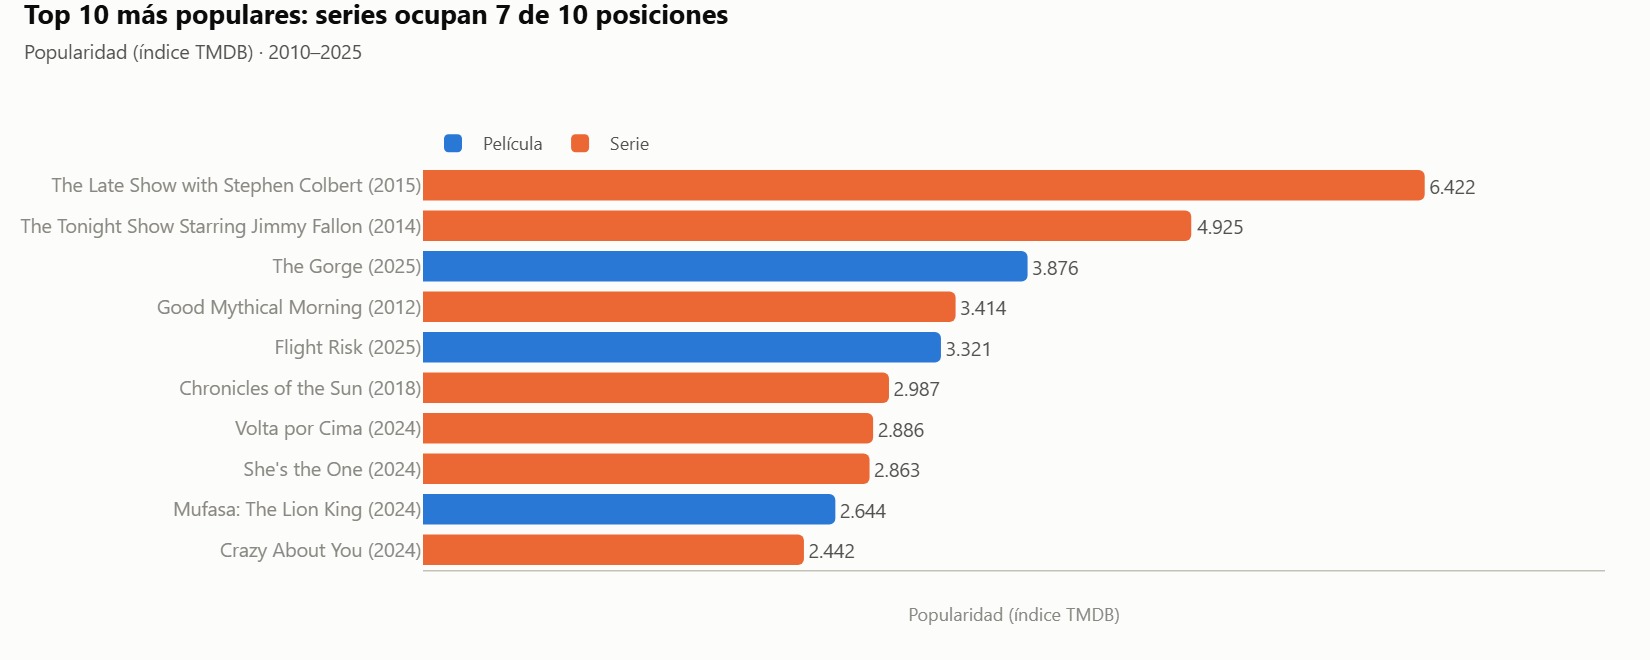

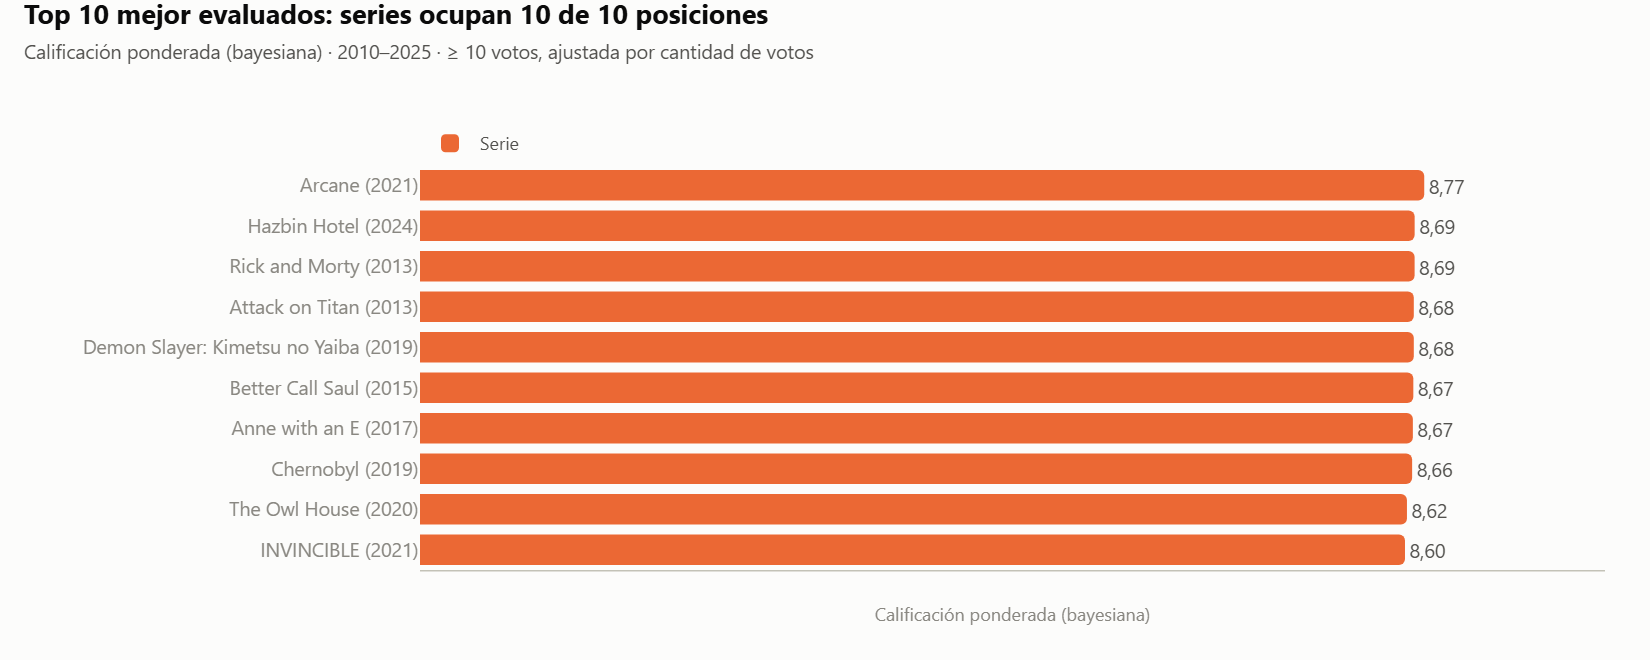

In [11]:
C.fig_top_titulos(cat, 'popularity').show()
C.fig_top_titulos(cat, 'nota_ponderada').show()

**Lectura:** los más populares son talk shows y telenovelas brasileñas recientes (*Volta por Cima*, *Crazy About You*)
y estrenos 2024–2025 de Hollywood. Los mejor evaluados (calificación bayesiana) son **todas series**, mayoritariamente
de **animación** (*Arcane*, *Attack on Titan*, *Demon Slayer*).
### Q: ¿La calidad está mejorando?
**Forma:** líneas (cambio continuo en el tiempo), 2025 con marcador hueco por datos incompletos.

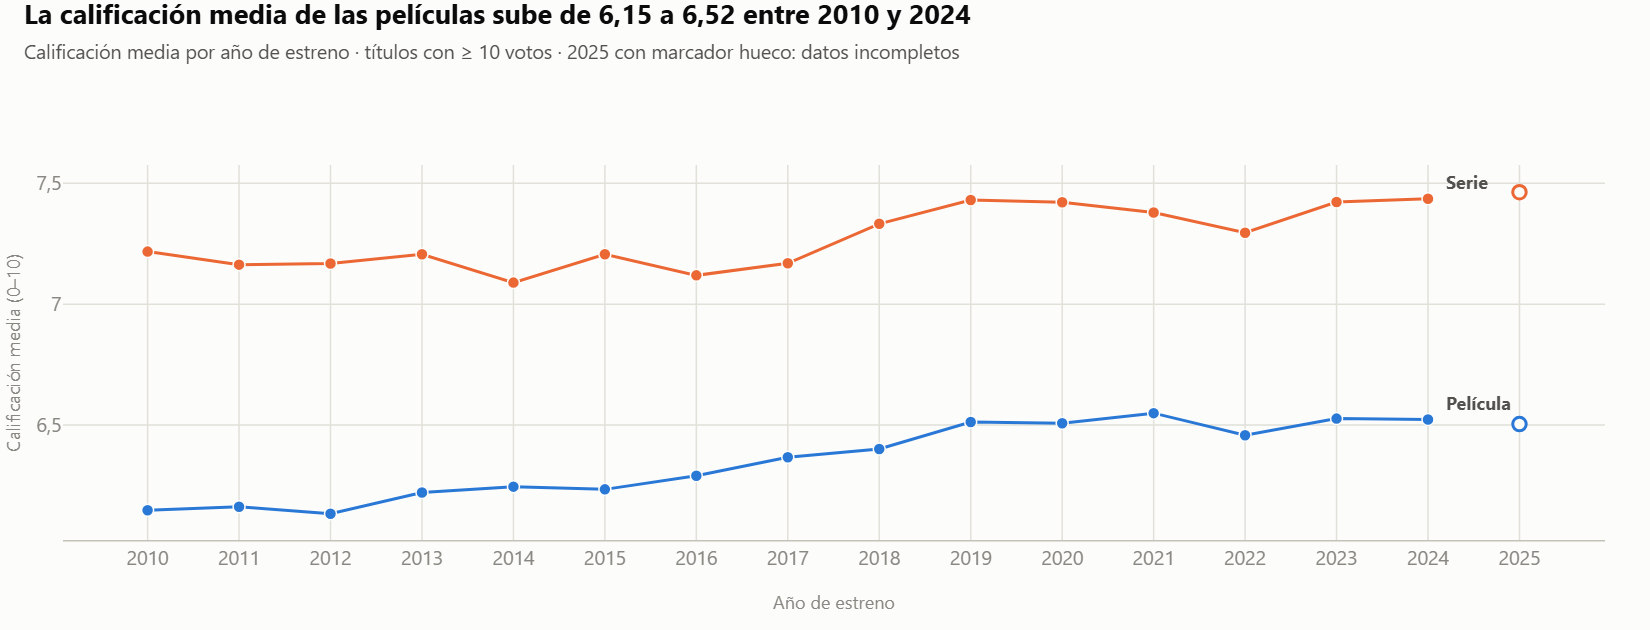

In [12]:
C.fig_tendencia_nota(cat).show()

---
# Acto 3 · ¿Qué evidencia lo demuestra? — Brechas de oferta y demanda
### Q: ¿Qué géneros concentran mayor popularidad respecto de lo que ofrecemos?
**Métrica propia — brecha oferta/demanda:** % del género dentro del 20% más popular − % del género en el catálogo.
**Forma:** barras divergentes desde 0 (small multiples por tipo). Color de foco = oportunidad; gris = sobre-oferta.

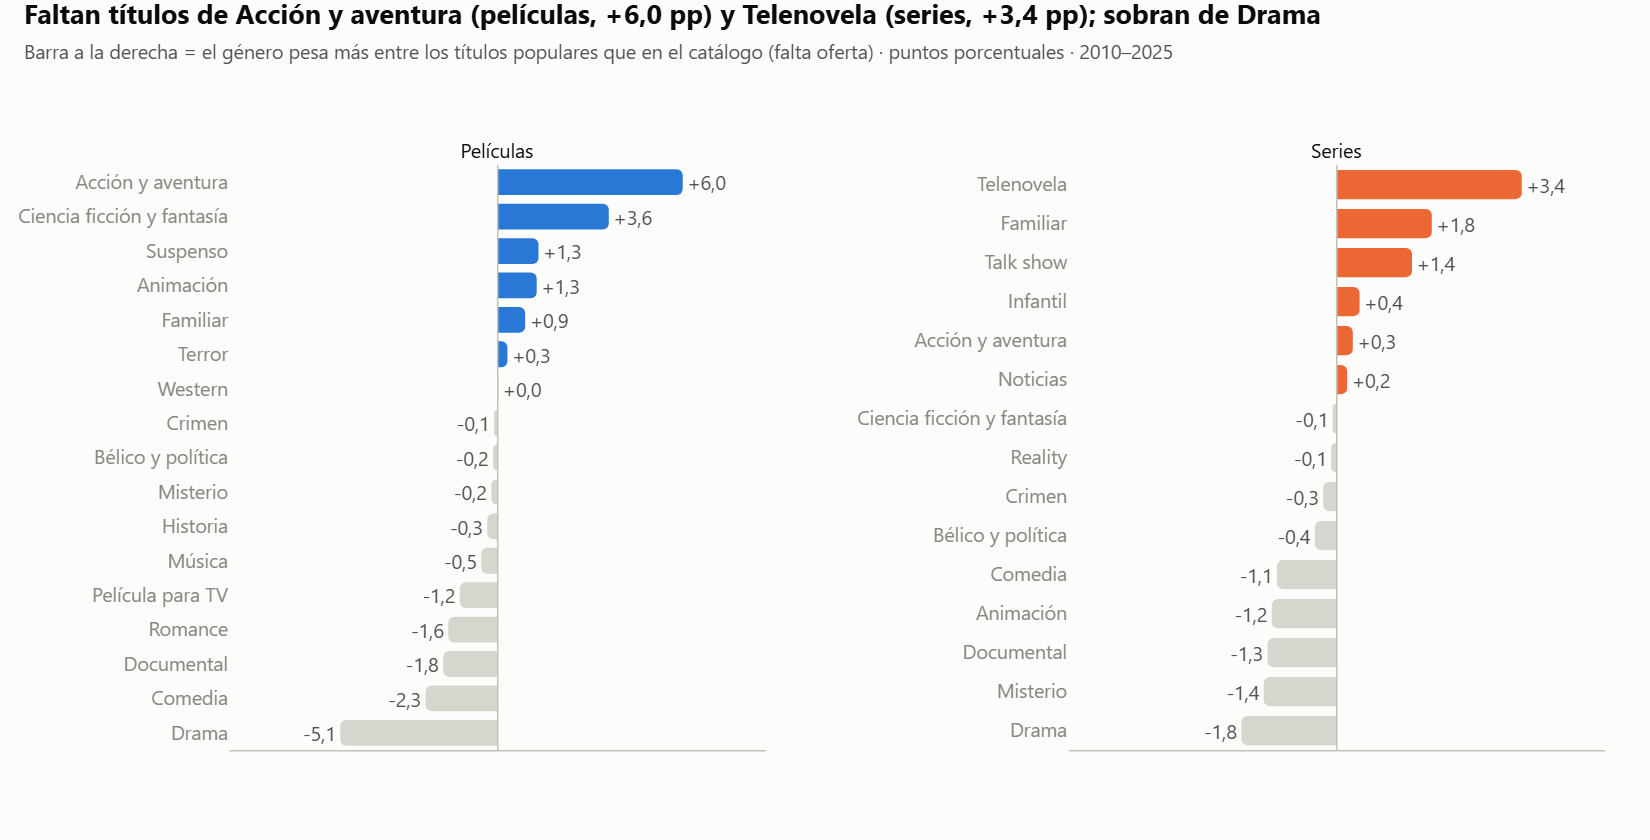

In [13]:
C.fig_brecha_generos(gen).show()

In [14]:
C.tabla_generos(gen).sort_values('brecha_pp', ascending=False)[['tipo','genero','titulos','share_catalogo','share_top20','brecha_pp','nota_media']].round(3).head(10)

,tipo,genero,titulos,share_catalogo,share_top20,brecha_pp,nota_media
0,Película,Acción y aventura,4157,0.114,0.174,6.005,6.325
3,Película,Ciencia ficción y fantasía,2730,0.075,0.111,3.606,6.313
31,Serie,Telenovela,631,0.022,0.057,3.425,7.136
25,Serie,Familiar,1542,0.054,0.072,1.759,7.335
30,Serie,Talk show,655,0.023,0.037,1.393,6.551
14,Película,Suspenso,3769,0.103,0.117,1.323,6.049
1,Película,Animación,1579,0.043,0.056,1.265,6.951
8,Película,Familiar,1472,0.040,0.049,0.891,6.679
26,Serie,Infantil,835,0.029,0.034,0.422,7.279
15,Película,Terror,2425,0.067,0.070,0.315,5.739


**Lectura:** en películas, **Acción y aventura (+6,0 pp)** y **Ciencia ficción y fantasía (+3,6 pp)** están
sobre-representadas entre los títulos más populares; en series, **Telenovela (+3,4 pp)** y **Familiar (+1,8 pp)**.
**Drama** está sobre-ofertado en ambos tipos (−5,1 pp en películas).
### Matriz de oportunidad: popularidad × calificación × oferta
**Forma:** gráfico de burbujas en cuadrantes (X = popularidad relativa 0–100 con 50 = título típico, Y = calificación, tamaño = cantidad de títulos).
Burbuja **pequeña** en el cuadrante superior derecho = género popular, bien evaluado y con poca oferta.

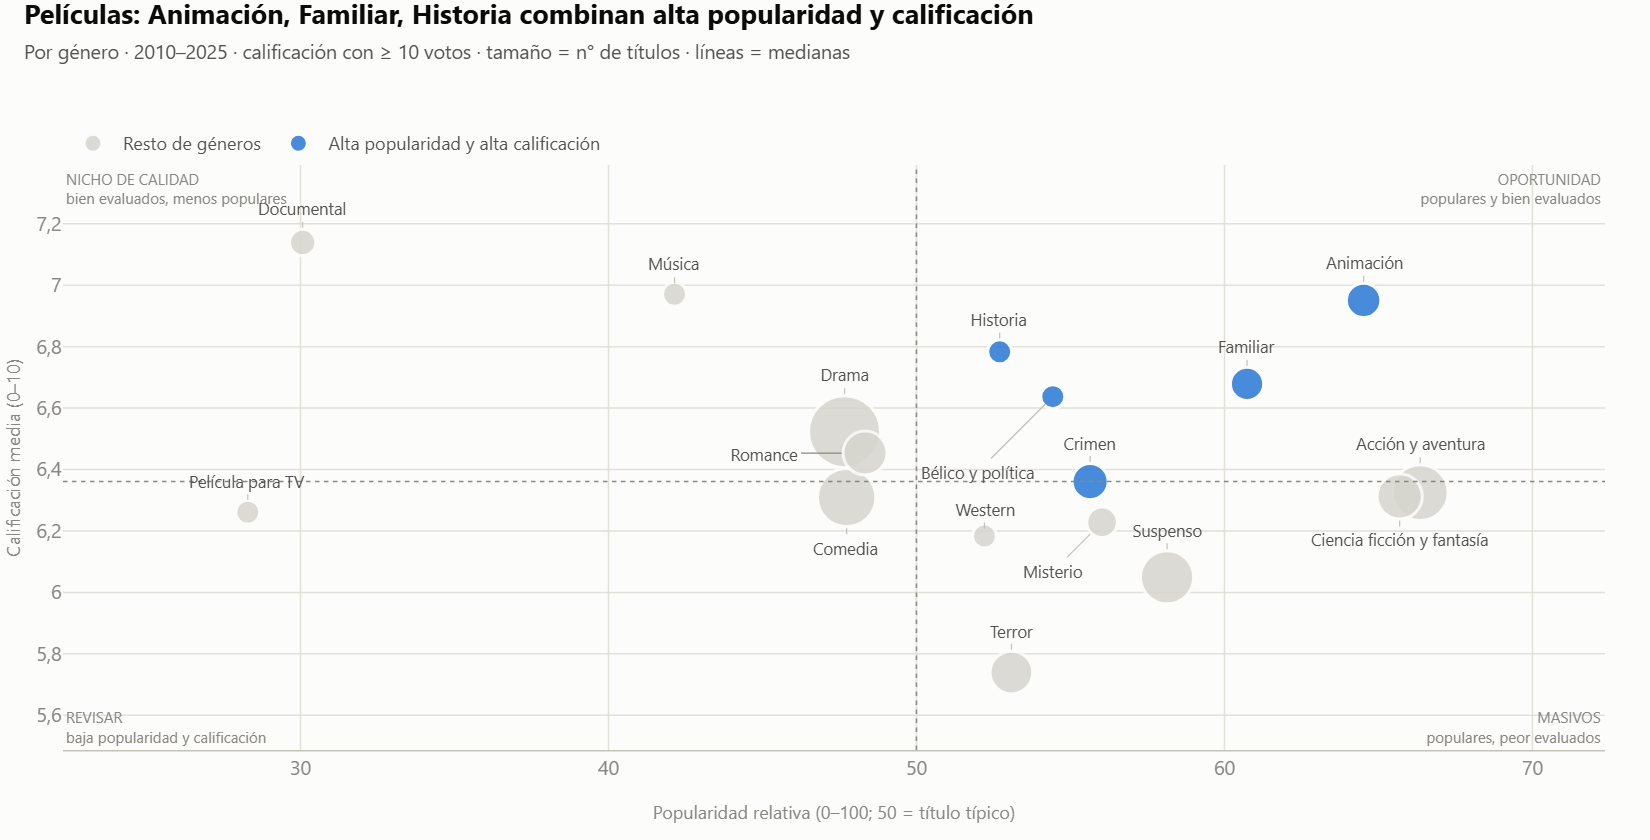

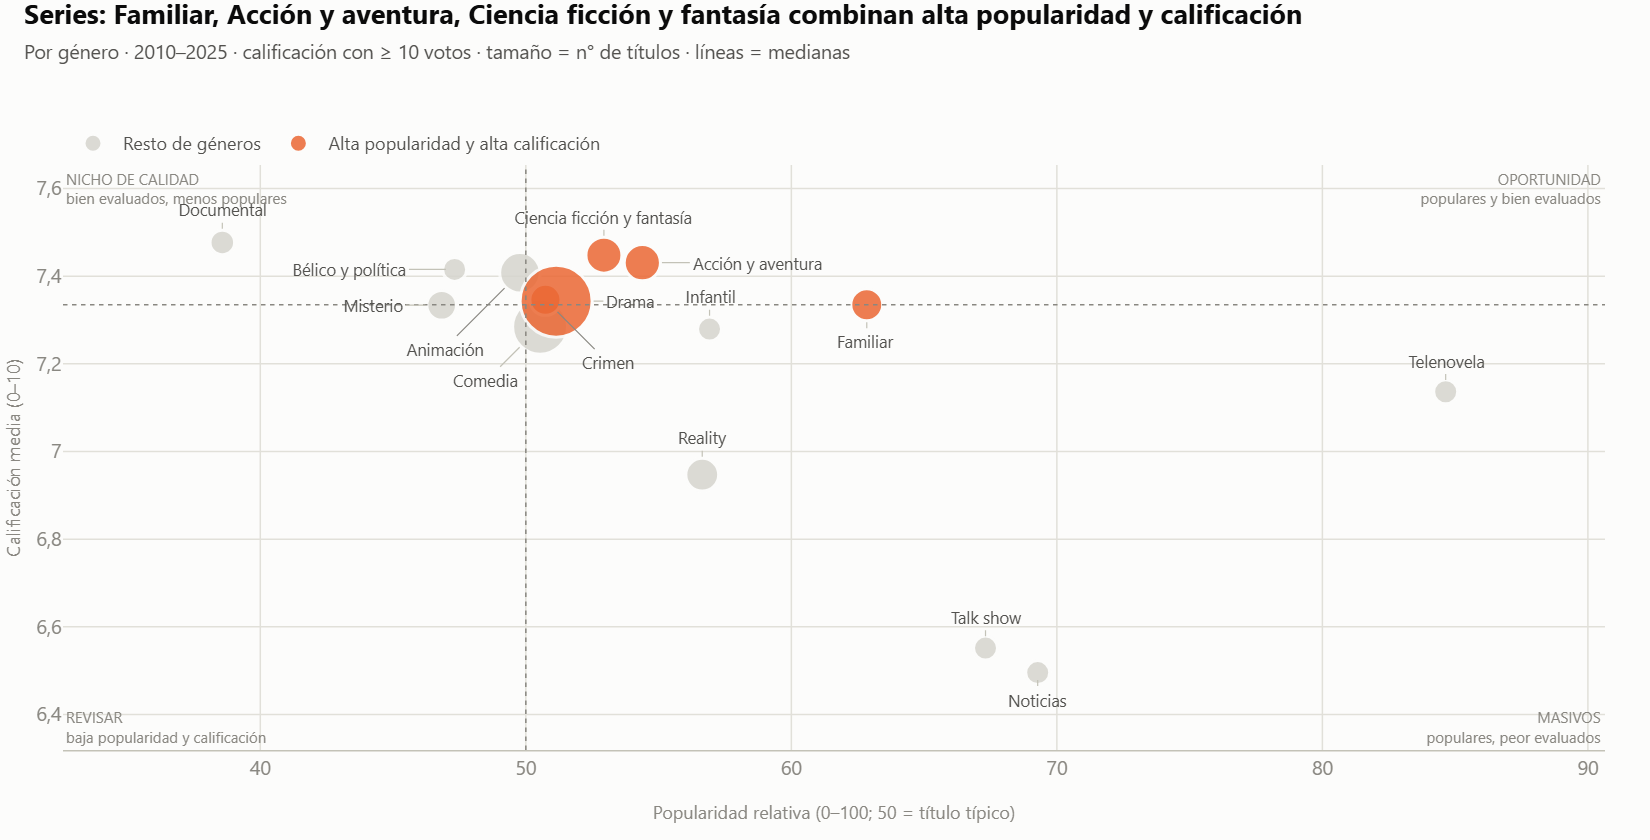

In [15]:
C.fig_matriz_oportunidad(gen, 'Película').show()
C.fig_matriz_oportunidad(gen, 'Serie').show()

**Lectura:** en películas, **Animación** es el caso más claro: popularidad relativa ~65 (típico = 50), la mejor calificación
de los géneros masivos (6,95) y solo 4% de la oferta. **Familiar** la sigue. En series, **Familiar** y
**Acción y aventura** combinan ambos atributos; **Telenovela** es la más popular (popularidad relativa ~85) aunque con nota
algo menor ("masivo").

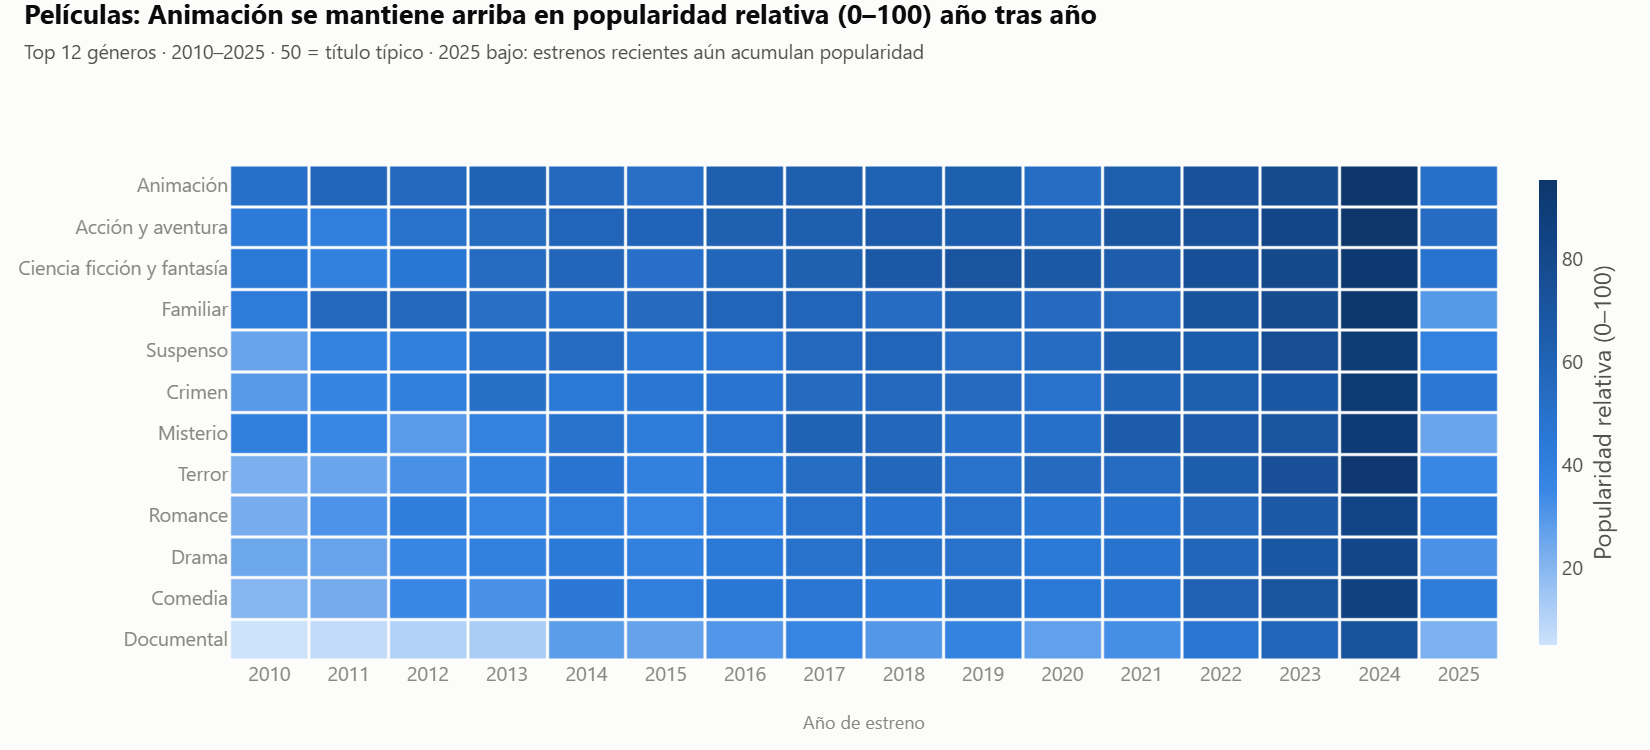

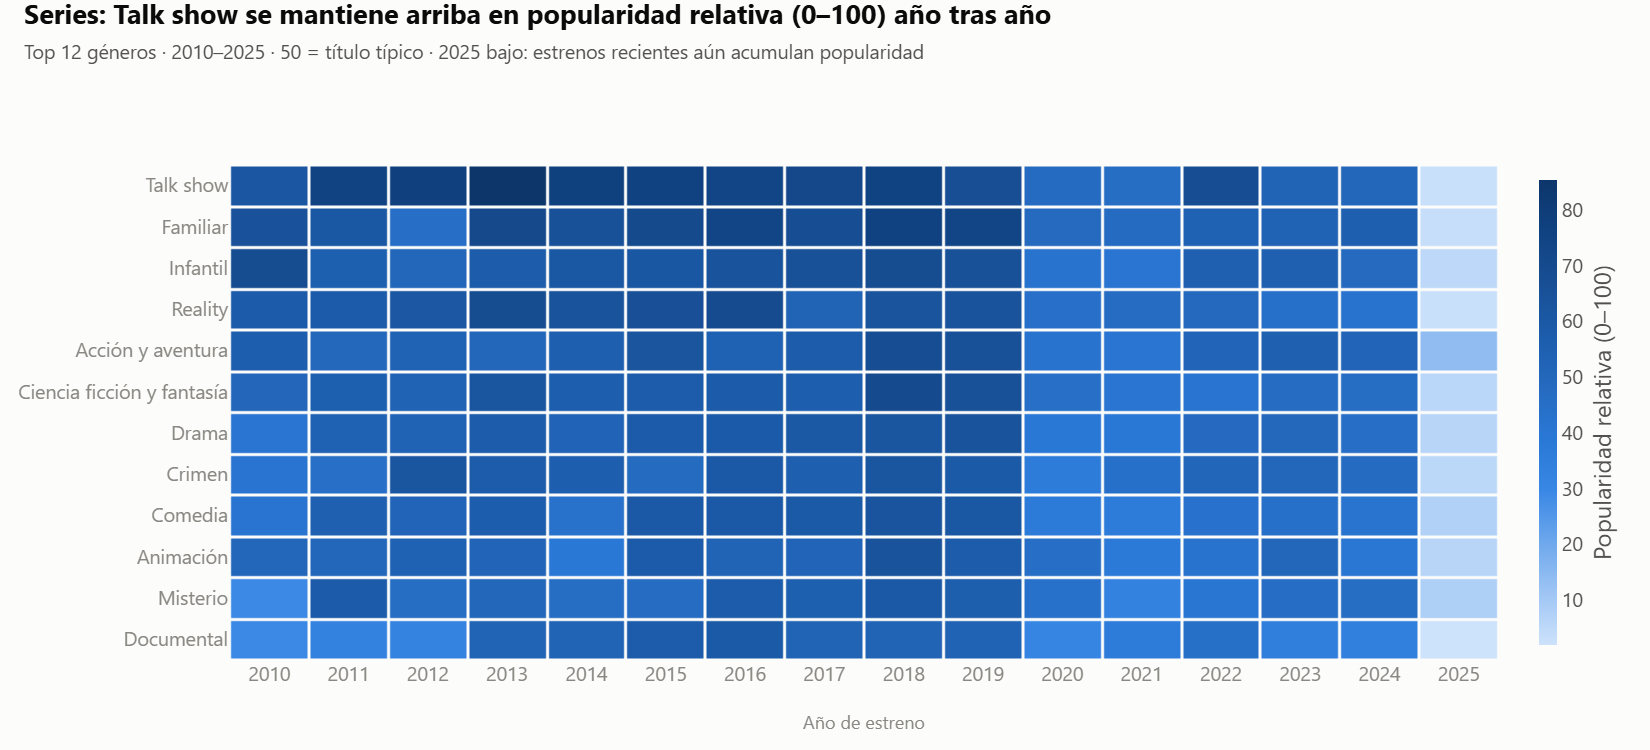

In [16]:
C.fig_heatmap_genero_anio(gen, 'Película').show()
C.fig_heatmap_genero_anio(gen, 'Serie').show()

### Q: ¿Qué mercados muestran mayor potencial? ¿Qué países tienen mejores valoraciones?
**Forma:** ranking de barras por popularidad relativa con el % del catálogo anotado (se lee sin escala log), Latinoamérica destacada; dot plot de calificación por país.

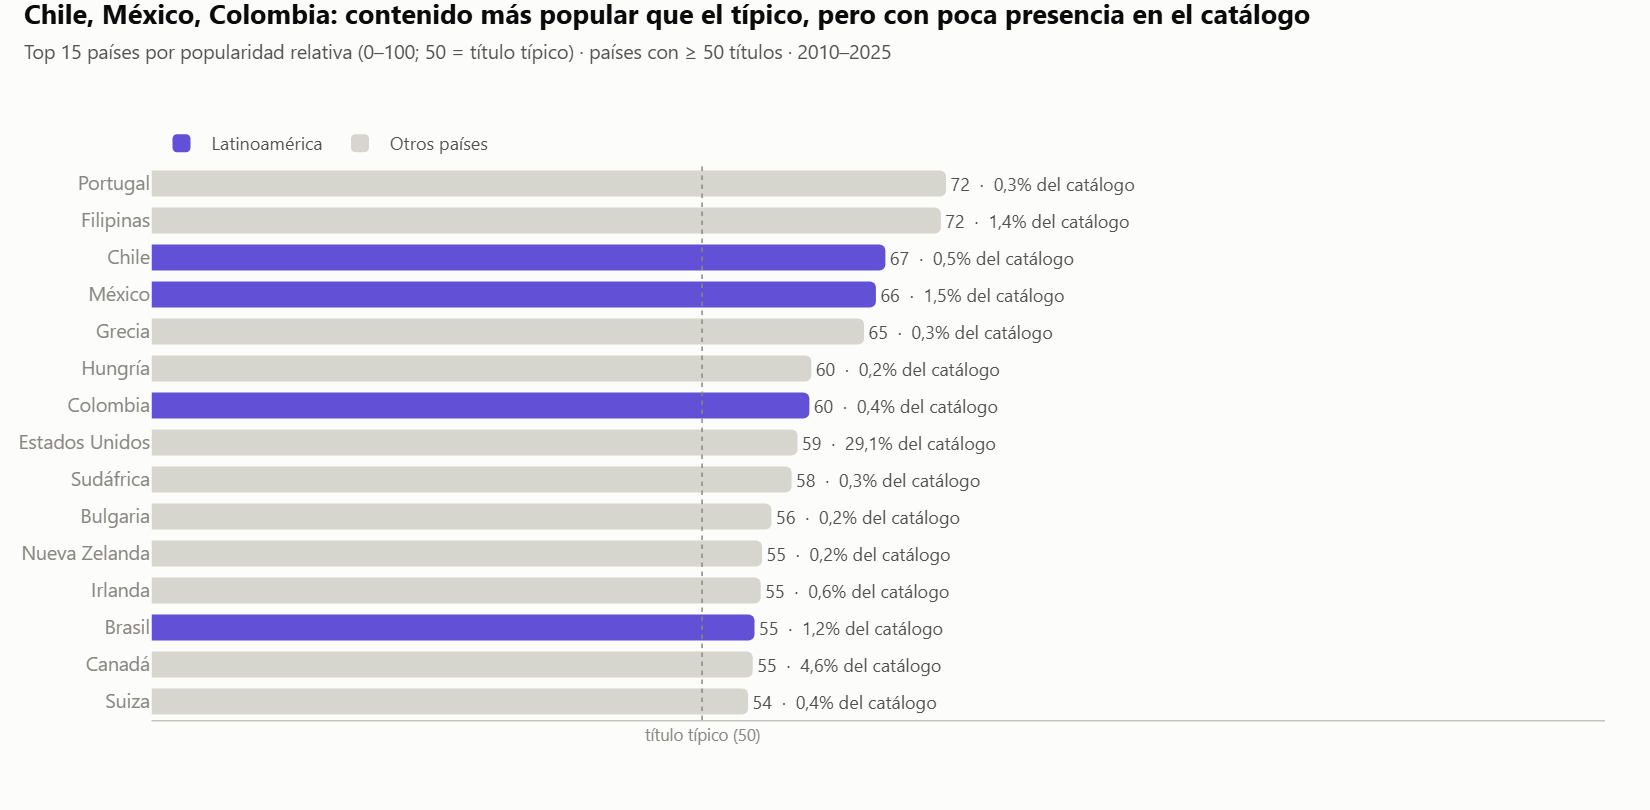

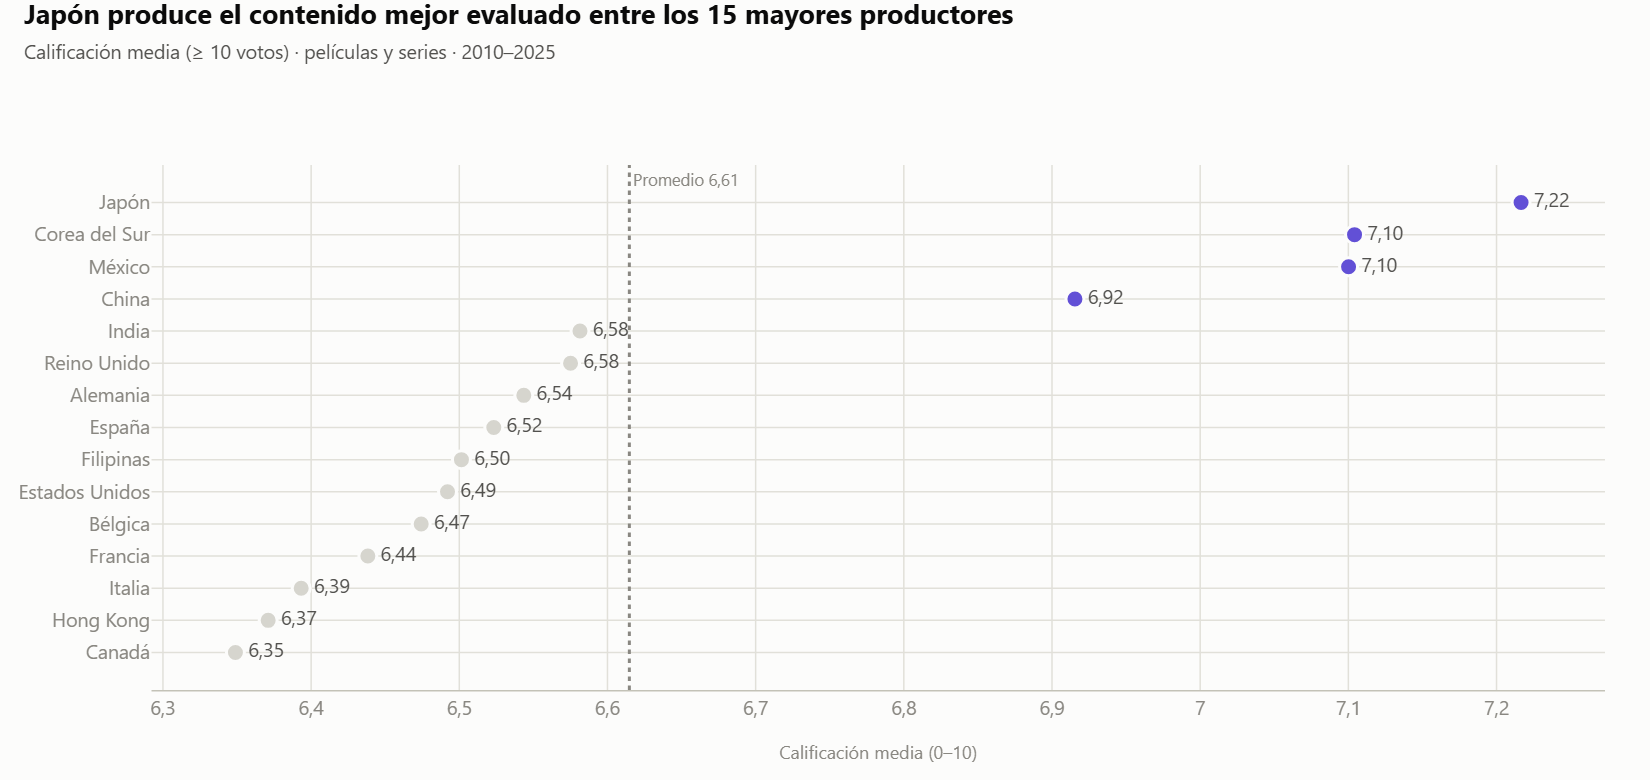

In [17]:
C.fig_mercados(pais).show()
C.fig_paises_nota(pais).show()

**Lectura:** **Chile, México y Colombia** tienen popularidad relativa de 60–67 (típico = 50) con muy poca oferta (México 1,5%,
Colombia y Chile < 0,5%). **Japón, Corea del Sur y México** producen el contenido mejor evaluado entre los 15 mayores
productores. Italia y Francia: mucha oferta, baja popularidad relativa.

### Q: Rentabilidad (solo películas)
**Forma:** dispersión log-log con líneas de referencia ROI 1x/5x; barras ordenadas de ROI mediano; barras por tramo.

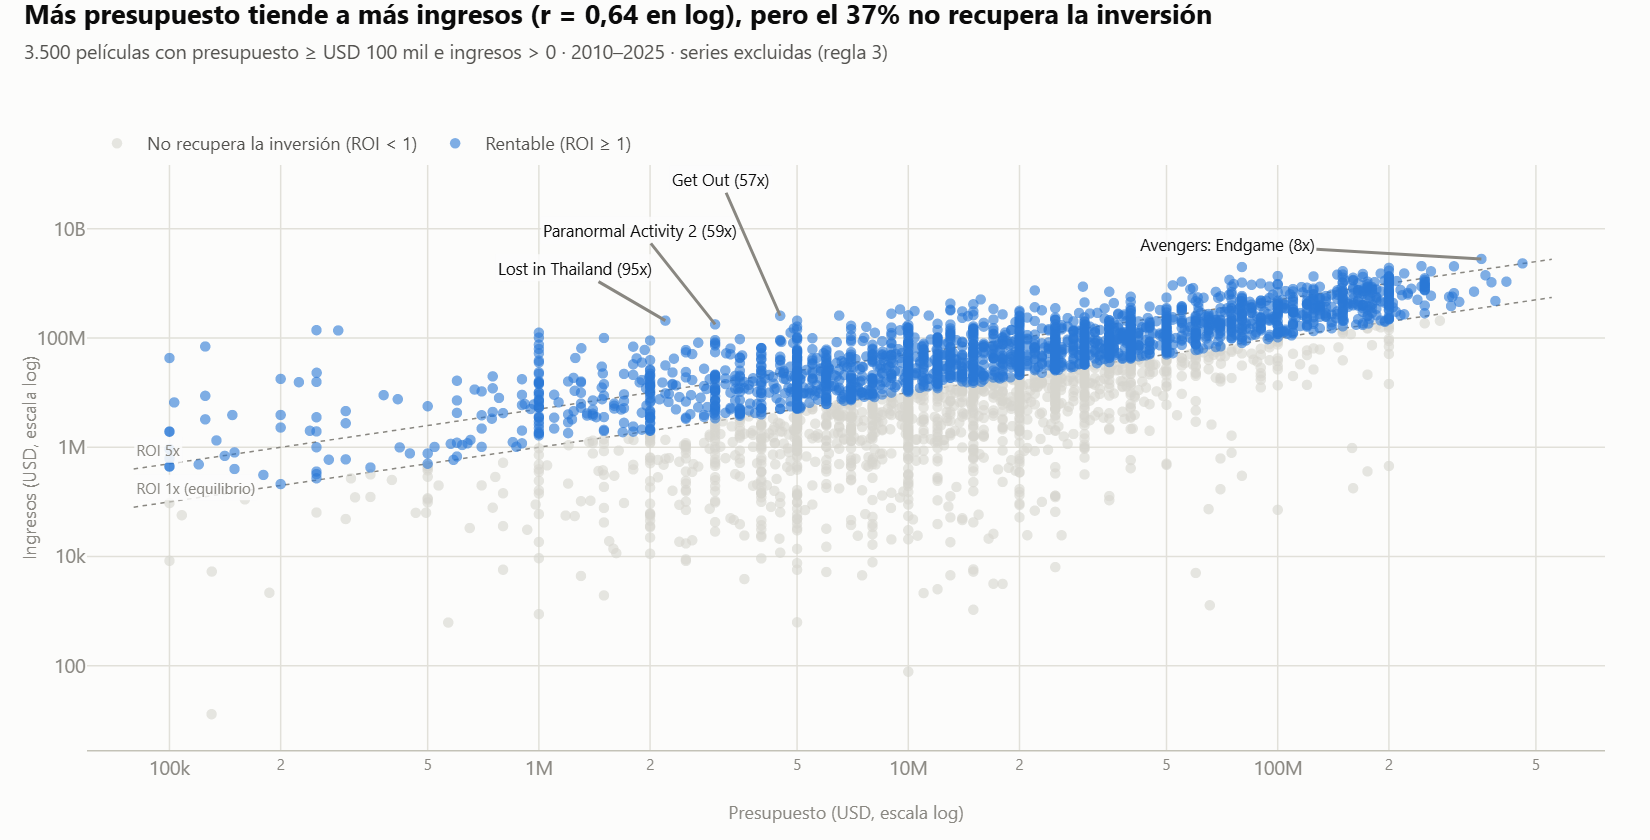

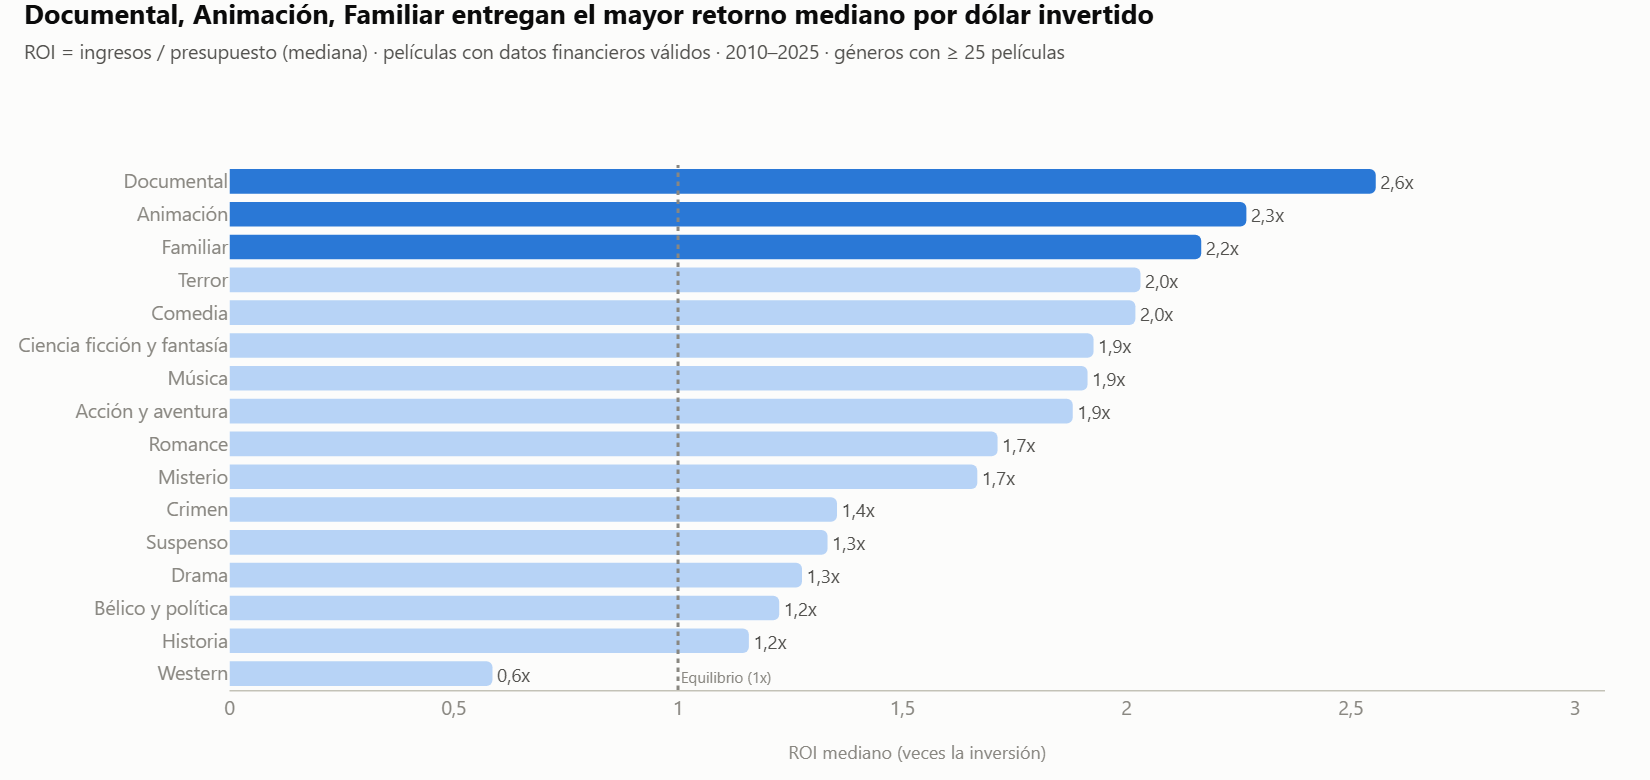

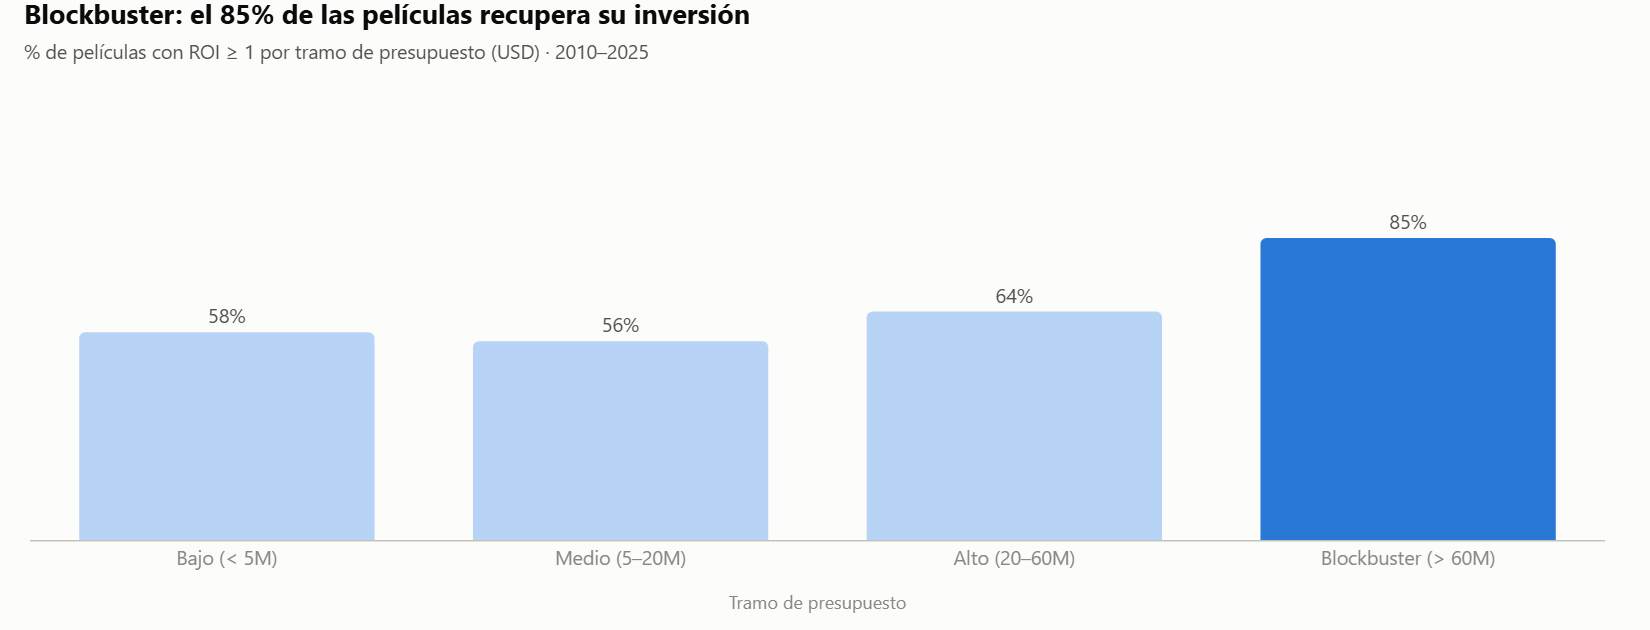

In [18]:
C.fig_presupuesto_ingresos(cat).show()
C.fig_roi_genero(gen).show()
C.fig_rentabilidad_tramo(cat).show()

In [19]:
C.tabla_joyas(cat, 10)

,title,release_year,genero_principal,pais_principal,budget,revenue,roi,nota
7023,Get Out,2017,Misterio,Estados Unidos,4500000.0,255407969.0,56.757326,7.600
2533,Lost in Thailand,2012,Comedia,China,2200000.0,208000000.0,94.545455,6.407
86,Paranormal Activity 2,2010,Terror,Estados Unidos,3000000.0,177512032.0,59.170677,5.800
6099,Lights Out,2016,Terror,Estados Unidos,4900000.0,149368835.0,30.483436,6.400
5339,Mr. Six,2015,Crimen,China,250000.0,139191345.0,556.765380,6.800
7739,Secret Superstar,2017,Drama,India,286284.0,137416709.0,480.001359,7.300
7134,Happy Death Day,2017,Comedia,Estados Unidos,4800000.0,125479266.0,26.141514,6.700
8732,Dragon Ball Super: Broly,2018,Acción y aventura,Japón,1000000.0,125002821.0,125.002821,7.900
2230,The Devil Inside,2012,Terror,Estados Unidos,1000000.0,101800000.0,101.800000,4.700
1020,Insidious,2011,Terror,Canadá,1500000.0,100106454.0,66.737636,6.939


**Lectura:** existe relación presupuesto–ingresos (r = 0,64 en log), pero **37% de las películas no recupera la
inversión**. **Animación y Familiar** combinan ROI mediano > 2x con 73–77% de títulos rentables. Los blockbusters
(> USD 60 M) son los más seguros (85% rentables). Terror/Misterio de bajo presupuesto generan los mayores
múltiplos (*Get Out* 57x), pero con alta varianza.

### Q: ¿Qué directores y actores aparecen con mayor frecuencia?

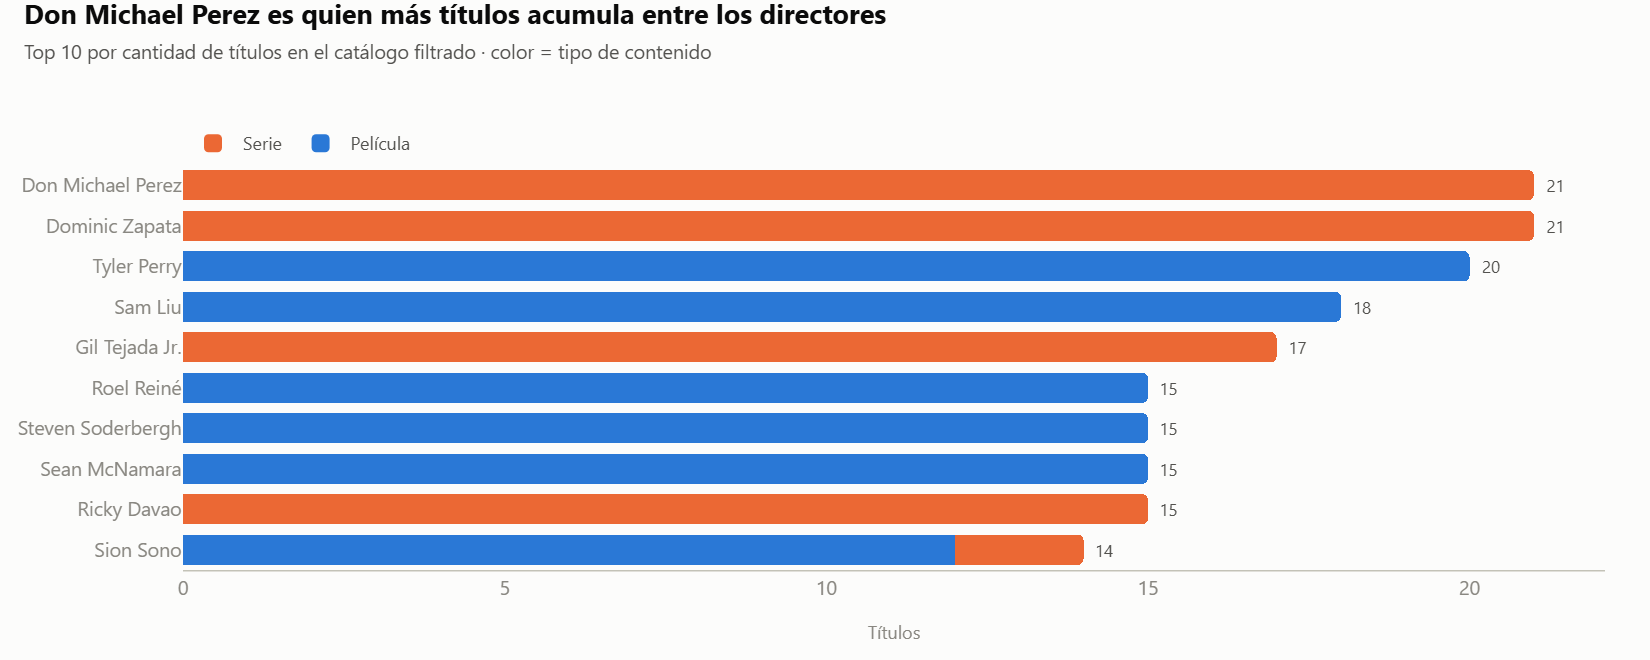

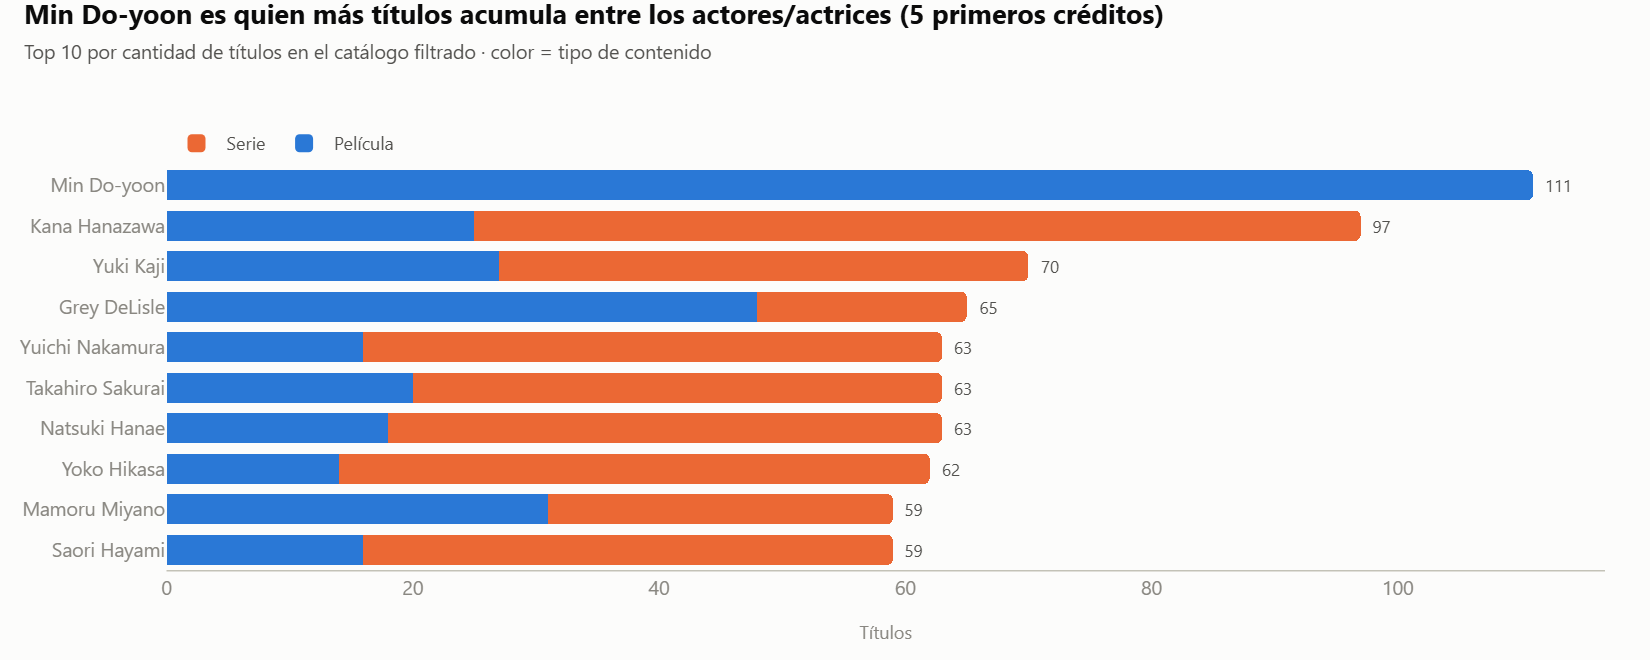

In [20]:
C.fig_top_personas(pers, 'Director').show()
C.fig_top_personas(pers, 'Actor/Actriz').show()

**Lectura:** los directores más frecuentes son de telenovelas filipinas (GMA) y cine estadounidense de nicho
(Tyler Perry). Entre actores dominan **actores de voz de anime** japonés (Kana Hanazawa, Yuki Kaji), lo que
confirma el peso del anime en el catálogo de series.

---
# Acto 4 · ¿Qué decisiones deberían tomarse?
| # | Recomendación para la Gerencia de Contenidos | Evidencia |
|---|---|---|
| 1 | **Aumentar la adquisición de Animación y Familiar** (películas y series) | Cuadrante de oportunidad; ROI mediano 2,2–2,3x; 73–77% rentables; top 10 mejor evaluados dominado por animación |
| 2 | **Crecer en contenido latinoamericano en español/portugués**, con foco en **telenovelas y reality** de México, Brasil y Colombia | Español: 5,1% del catálogo, popularidad relativa 58; Telenovela +3,4 pp de brecha; Chile/México/Colombia 60–67 |
| 3 | **Reducir la adquisición incremental de Drama** y reasignar presupuesto | Drama: −5,1 pp (películas) y −1,8 pp (series); ROI mediano 1,3x |
| 4 | **Mantener un pipeline asiático de calidad** (Japón, Corea) | Mejor calificación media por país (7,22 y 7,10) |
| 5 | **Portafolio de películas balanceado:** blockbusters para estabilidad + apuestas de bajo presupuesto en terror/misterio | 85% rentables > USD 60 M; joyas de bajo presupuesto con ROI 20–95x |
| 6 | **Exigir a la fuente datos de clasificación etaria y duración** | Hoy no es posible calcular los KPIs de clasificación |